In [1]:
import pandas as pd
import numpy as np

# Load the data
df = pd.read_csv("indian_roads_dataset.csv")

# Keep an untouched backup so you can always go back
raw = df.copy()

# Quick confirmation that it loaded
print(df.shape)
df.head()

(20000, 24)


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,22-10-2023,05:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,21-05-2023,04:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,10-07-2024,13:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,30-03-2025,11:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,25-01-2024,16:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10


In [7]:

df.columns.tolist()

['accident_id',
 'city',
 'state',
 'latitude',
 'longitude',
 'date',
 'time',
 'hour',
 'day_of_week',
 'is_weekend',
 'road_type',
 'lanes',
 'traffic_signal',
 'weather',
 'visibility',
 'temperature',
 'traffic_density',
 'cause',
 'accident_severity',
 'vehicles_involved',
 'casualties',
 'is_peak_hour',
 'festival',
 'risk_score']

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   accident_id        20000 non-null  int64  
 1   city               20000 non-null  object 
 2   state              20000 non-null  object 
 3   latitude           20000 non-null  float64
 4   longitude          20000 non-null  float64
 5   date               20000 non-null  object 
 6   time               20000 non-null  object 
 7   hour               20000 non-null  int64  
 8   day_of_week        20000 non-null  object 
 9   is_weekend         20000 non-null  int64  
 10  road_type          20000 non-null  object 
 11  lanes              20000 non-null  int64  
 12  traffic_signal     20000 non-null  int64  
 13  weather            20000 non-null  object 
 14  visibility         20000 non-null  object 
 15  temperature        20000 non-null  int64  
 16  traffic_density    200

In [6]:
df.describe()

,accident_id,latitude,longitude,hour,is_weekend,lanes,traffic_signal,temperature,vehicles_involved,casualties,is_peak_hour,risk_score
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,9999.500000,20.389207,78.173330,11.487200,0.286150,3.493950,0.499850,27.579600,2.992000,1.726450,0.247400,0.437585
std,5773.647028,6.165791,4.485967,6.945563,0.451972,1.705406,0.500012,7.454746,1.415534,1.489104,0.431512,0.218130
min,0.000000,12.800172,72.700017,0.000000,0.000000,1.000000,0.000000,15.000000,1.000000,0.000000,0.000000,0.100000
25%,4999.750000,13.198653,73.997979,5.000000,0.000000,2.000000,0.000000,21.000000,2.000000,1.000000,0.000000,0.250000
50%,9999.500000,18.812008,77.297000,12.000000,0.000000,4.000000,0.000000,28.000000,3.000000,1.000000,0.000000,0.450000
75%,14999.250000,28.402467,80.111089,18.000000,1.000000,5.000000,1.000000,34.000000,4.000000,3.000000,0.000000,0.600000
max,19999.000000,30.799960,88.499861,23.000000,1.000000,6.000000,1.000000,40.000000,5.000000,5.000000,1.000000,1.000000


In [8]:
df.describe(include="object").T

,count,unique,top,freq
city,20000,8,Chandigarh,2577
state,20000,7,Maharashtra,5009
date,20000,1201,03-11-2022,30
time,20000,24,02:00,888
day_of_week,20000,7,Monday,2966
road_type,20000,3,urban,6745
weather,20000,3,clear,6690
visibility,20000,3,low,9987
traffic_density,20000,3,low,7067
cause,20000,5,distraction,4026


In [9]:
df.isnull()

,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
19996,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
19997,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
19998,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


In [10]:
df.isna().sum()

accident_id              0
city                     0
state                    0
latitude                 0
longitude                0
date                     0
time                     0
hour                     0
day_of_week              0
is_weekend               0
road_type                0
lanes                    0
traffic_signal           0
weather                  0
visibility               0
temperature              0
traffic_density          0
cause                    0
accident_severity        0
vehicles_involved        0
casualties               0
is_peak_hour             0
festival             19885
risk_score               0
dtype: int64

In [11]:
df["festival"].value_counts(dropna=False)

festival
NaN         19885
Holi           38
Eid            34
Diwali         31
New Year       12
Name: count, dtype: int64

In [12]:
# Replace NaN with a meaningful label
df["festival"] = df["festival"].fillna("No Festival")

# Add a 0/1 flag
df["is_festival"] = (df["festival"] != "No Festival").astype(int)

# Verify
print("Total missing values:", df.isna().sum().sum())
print(df["festival"].value_counts())
print(df["is_festival"].value_counts())

Total missing values: 0
festival
No Festival    19885
Holi              38
Eid               34
Diwali            31
New Year          12
Name: count, dtype: int64
is_festival
0    19885
1      115
Name: count, dtype: int64


In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [14]:
print("Is accident_id unique?", df["accident_id"].is_unique)
print("Unique IDs:", df["accident_id"].nunique(), "out of", len(df))

Is accident_id unique? True
Unique IDs: 20000 out of 20000


In [15]:
cols = ["city", "date", "time", "latitude", "longitude"]
print("Same place and time:", df.duplicated(subset=cols).sum())

Same place and time: 0


In [16]:
# 1. Convert date from text to a real date (day-month-year)
df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y")

# 2. Convert label columns to category
cat_cols = ["city", "state", "day_of_week", "road_type", "weather",
            "visibility", "traffic_density", "cause",
            "accident_severity", "festival"]
df[cat_cols] = df[cat_cols].astype("category")

# 3. Verify
df.info()
print(df["date"].min(), "to", df["date"].max())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   accident_id        20000 non-null  int64         
 1   city               20000 non-null  category      
 2   state              20000 non-null  category      
 3   latitude           20000 non-null  float64       
 4   longitude          20000 non-null  float64       
 5   date               20000 non-null  datetime64[ns]
 6   time               20000 non-null  object        
 7   hour               20000 non-null  int64         
 8   day_of_week        20000 non-null  category      
 9   is_weekend         20000 non-null  int64         
 10  road_type          20000 non-null  category      
 11  lanes              20000 non-null  int64         
 12  traffic_signal     20000 non-null  int64         
 13  weather            20000 non-null  category      
 14  visibi

In [17]:
# 1. Look at the unique values per label column
for c in cat_cols:
    print(c, "->", df[c].nunique(), "unique:", list(df[c].cat.categories))

# 2. Clean spacing and capitalisation
for c in cat_cols:
    df[c] = df[c].astype(str).str.strip().str.title().astype("category")

# 3. Verify
print()
for c in cat_cols:
    print(c, df[c].nunique(), "unique")

spaces = sum((df[c].astype(str) != df[c].astype(str).str.strip()).sum() for c in cat_cols)
print("Values with extra spaces:", spaces)

city -> 8 unique: ['Bangalore', 'Chandigarh', 'Chennai', 'Delhi', 'Hyderabad', 'Kolkata', 'Mumbai', 'Pune']
state -> 7 unique: ['Delhi', 'Karnataka', 'Maharashtra', 'Punjab', 'Tamil Nadu', 'Telangana', 'West Bengal']
day_of_week -> 7 unique: ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
road_type -> 3 unique: ['highway', 'rural', 'urban']
weather -> 3 unique: ['clear', 'fog', 'rain']
visibility -> 3 unique: ['high', 'low', 'medium']
traffic_density -> 3 unique: ['high', 'low', 'medium']
cause -> 5 unique: ['distraction', 'drunk driving', 'overspeeding', 'poor road', 'weather']
accident_severity -> 3 unique: ['fatal', 'major', 'minor']
festival -> 5 unique: ['Diwali', 'Eid', 'Holi', 'New Year', 'No Festival']

city 8 unique
state 7 unique
day_of_week 7 unique
road_type 3 unique
weather 3 unique
visibility 3 unique
traffic_density 3 unique
cause 5 unique
accident_severity 3 unique
festival 5 unique
Values with extra spaces: 0


In [18]:
# day_of_week should match the actual date
print("Day mismatch:", (df["date"].dt.day_name() != df["day_of_week"].astype(str)).sum())

# is_weekend should be 1 only for Saturday/Sunday
expected_weekend = df["day_of_week"].astype(str).isin(["Saturday", "Sunday"]).astype(int)
print("Weekend flag mismatch:", (expected_weekend != df["is_weekend"]).sum())

# hour should match the time column
print("Hour vs time mismatch:", (df["time"].str[:2].astype(int) != df["hour"]).sum())

Day mismatch: 0
Weekend flag mismatch: 0
Hour vs time mismatch: 0


In [19]:
# Cell 2: severity vs casualties
print("Fatal with 0 casualties:",
      ((df["accident_severity"] == "Fatal") & (df["casualties"] == 0)).sum())
print(df.groupby("accident_severity", observed=True)["casualties"].describe())

# Cell 3: one state per city
print("\nMax states per city:", df.groupby("city", observed=True)["state"].nunique().max())

# Cell 4: coordinate ranges per city
print()
print(df.groupby("city", observed=True)[["latitude", "longitude"]].agg(["min", "max"]).round(2))


Fatal with 0 casualties: 0
                     count      mean       std  min  25%  50%  75%  max
accident_severity                                                      
Fatal               2987.0  3.001674  1.416224  1.0  2.0  3.0  4.0  5.0
Major               5988.0  1.494823  1.376437  0.0  0.0  1.0  2.0  5.0
Minor              11025.0  1.506757  1.390140  0.0  0.0  1.0  2.0  5.0

Max states per city: 1

           latitude       longitude      
                min   max       min   max
city                                     
Bangalore      12.8  13.2      77.4  77.8
Chandigarh     30.6  30.8      76.7  76.9
Chennai        12.8  13.2      80.1  80.3
Delhi          28.4  28.9      76.8  77.3
Hyderabad      17.2  17.6      78.2  78.6
Kolkata        22.4  22.7      88.2  88.5
Mumbai         18.8  19.3      72.7  73.0
Pune           18.4  18.7      73.7  74.0


In [20]:
num_cols = ["temperature", "lanes", "vehicles_involved", "casualties", "risk_score"]

for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[c] < low) | (df[c] > high)).sum()
    print(f"{c:18} range allowed: {low:.2f} to {high:.2f} | outliers: {n}")

temperature        range allowed: 1.50 to 53.50 | outliers: 0
lanes              range allowed: -2.50 to 9.50 | outliers: 0
vehicles_involved  range allowed: -1.00 to 7.00 | outliers: 0
casualties         range allowed: -2.00 to 6.00 | outliers: 0
risk_score         range allowed: -0.27 to 1.12 | outliers: 0


In [21]:
# 1. Pull parts out of the date
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()

# 2. Group hours into time-of-day buckets
df["time_of_day"] = pd.cut(
    df["hour"],
    bins=[-1, 5, 11, 16, 20, 23],
    labels=["Night", "Morning", "Afternoon", "Evening", "Late Night"]
)

# 3. Casualties per vehicle (a rough severity measure)
df["casualty_per_vehicle"] = (df["casualties"] / df["vehicles_involved"]).round(2)

# 4. Drop the redundant column (hour already holds this information)
df = df.drop(columns=["time"])

# 5. Verify
print(df[["date", "year", "month", "month_name", "hour", "time_of_day", "casualty_per_vehicle"]].head())
print()
print(df["time_of_day"].value_counts().sort_index())
print(df["year"].value_counts().sort_index())
print("Shape:", df.shape)

        date  year  month month_name  hour time_of_day  casualty_per_vehicle
0 2023-10-22  2023     10    October     5       Night                  1.00
1 2023-05-21  2023      5        May     4       Night                  0.75
2 2024-07-10  2024      7       July    13   Afternoon                  1.00
3 2025-03-30  2025      3      March    11     Morning                  0.40
4 2024-01-25  2024      1    January    16   Afternoon                  0.50

time_of_day
Night         5043
Morning       4907
Afternoon     4180
Evening       3362
Late Night    2508
Name: count, dtype: int64
year
2022    6117
2023    6088
2024    6061
2025    1734
Name: count, dtype: int64
Shape: (20000, 29)


In [22]:
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("time_of_day missing:", df["time_of_day"].isna().sum())
df.info()

Shape: (20000, 29)
Missing values: 0
Duplicate rows: 0
time_of_day missing: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   accident_id           20000 non-null  int64         
 1   city                  20000 non-null  category      
 2   state                 20000 non-null  category      
 3   latitude              20000 non-null  float64       
 4   longitude             20000 non-null  float64       
 5   date                  20000 non-null  datetime64[ns]
 6   hour                  20000 non-null  int64         
 7   day_of_week           20000 non-null  category      
 8   is_weekend            20000 non-null  int64         
 9   road_type             20000 non-null  category      
 10  lanes                 20000 non-null  int64         
 11  traffic_signal        20000 non-null  int64         
 

In [23]:
# Save
df.to_csv("indian_roads_clean.csv", index=False)

# Reload to prove it worked
check = pd.read_csv("indian_roads_clean.csv", parse_dates=["date"])
print(check.shape)
print(check["date"].dtype)
check.head(3)

(20000, 29)
datetime64[ns]


,accident_id,city,state,latitude,longitude,date,hour,day_of_week,is_weekend,road_type,...,casualties,is_peak_hour,festival,risk_score,is_festival,year,month,month_name,time_of_day,casualty_per_vehicle
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,5,Sunday,1,Highway,...,2,0,No Festival,0.85,0,2023,10,October,Night,1.00
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,4,Sunday,1,Urban,...,3,0,No Festival,0.10,0,2023,5,May,Night,0.75
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13,Wednesday,0,Urban,...,1,0,No Festival,0.45,0,2024,7,July,Afternoon,1.00


In [24]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("indian_roads_clean.csv", parse_dates=["date"])

In [25]:
counts = df["accident_severity"].value_counts()
share = df["accident_severity"].value_counts(normalize=True).mul(100).round(1)

print(pd.DataFrame({"accidents": counts, "percent": share}))

                   accidents  percent
accident_severity                    
Minor                  11025     55.1
Major                   5988     29.9
Fatal                   2987     14.9


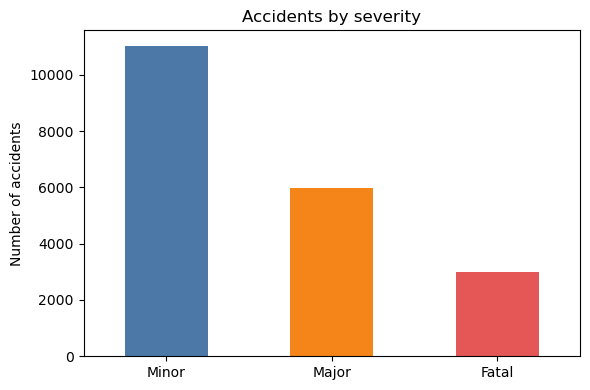

In [26]:
ax = counts.plot(kind="bar", color=["#4C78A8", "#F58518", "#E45756"], figsize=(6, 4))
ax.set_title("Accidents by severity")
ax.set_xlabel("")
ax.set_ylabel("Number of accidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
# 1 if the accident was fatal, 0 otherwise
df["is_fatal"] = (df["accident_severity"] == "Fatal").astype(int)

by_cause = (
    df.groupby("cause")
      .agg(accidents=("accident_id", "count"),
           fatal=("is_fatal", "sum"),
           fatal_rate=("is_fatal", "mean"))
)
by_cause["fatal_rate"] = (by_cause["fatal_rate"] * 100).round(1)

by_cause = by_cause.sort_values("fatal_rate", ascending=False)
print(by_cause)
print("\nOverall fatal rate:", round(df["is_fatal"].mean() * 100, 1), "%")

               accidents  fatal  fatal_rate
cause                                      
Poor Road           3974    623        15.7
Drunk Driving       3978    618        15.5
Overspeeding        4025    603        15.0
Weather             3997    601        15.0
Distraction         4026    542        13.5

Overall fatal rate: 14.9 %


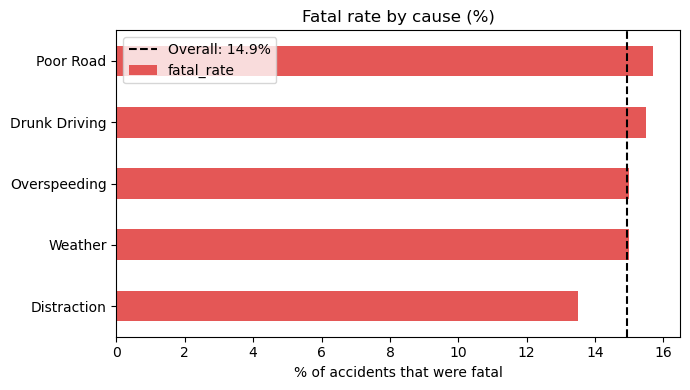

In [28]:
overall = df["is_fatal"].mean() * 100

ax = by_cause["fatal_rate"].sort_values().plot(kind="barh", figsize=(7, 4), color="#E45756")
ax.axvline(overall, color="black", linestyle="--", label=f"Overall: {overall:.1f}%")
ax.set_title("Fatal rate by cause (%)")
ax.set_xlabel("% of accidents that were fatal")
ax.set_ylabel("")
ax.legend()
plt.tight_layout()
plt.show()

In [29]:
from scipy.stats import chi2_contingency

ct = pd.crosstab(df["cause"], df["is_fatal"])
chi2, p, dof, expected = chi2_contingency(ct)

print(ct)
print(f"\nchi2 = {chi2:.2f}, degrees of freedom = {dof}, p-value = {p:.4f}")

is_fatal          0    1
cause                   
Distraction    3484  542
Drunk Driving  3360  618
Overspeeding   3422  603
Poor Road      3351  623
Weather        3396  601

chi2 = 9.76, degrees of freedom = 4, p-value = 0.0447


In [30]:
# Expected counts if cause made no difference
print(pd.DataFrame(expected, index=ct.index, columns=["not fatal", "fatal"]).round(1))

# Repeat the test for other columns
print()
for col in ["cause", "road_type", "weather", "traffic_density"]:
    ct2 = pd.crosstab(df[col], df["is_fatal"])
    chi2, p, dof, _ = chi2_contingency(ct2)
    print(f"{col:16} chi2 = {chi2:5.2f}   p = {p:.4f}")

               not fatal  fatal
cause                          
Distraction       3424.7  601.3
Drunk Driving     3383.9  594.1
Overspeeding      3423.9  601.1
Poor Road         3380.5  593.5
Weather           3400.0  597.0

cause            chi2 =  9.76   p = 0.0447
road_type        chi2 =  2.03   p = 0.3618
weather          chi2 =  0.09   p = 0.9551
traffic_density  chi2 =  0.07   p = 0.9664


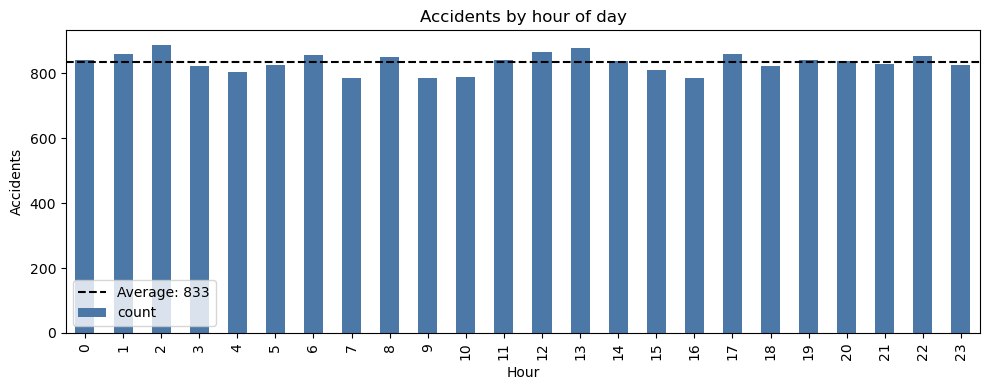

Busiest hour: 2 with 888
Quietest hour: 7 with 786


In [31]:
by_hour = df["hour"].value_counts().sort_index()

ax = by_hour.plot(kind="bar", figsize=(10, 4), color="#4C78A8")
ax.axhline(by_hour.mean(), color="black", linestyle="--", label=f"Average: {by_hour.mean():.0f}")
ax.set_title("Accidents by hour of day")
ax.set_xlabel("Hour")
ax.set_ylabel("Accidents")
ax.legend()
plt.tight_layout()
plt.show()

print("Busiest hour:", by_hour.idxmax(), "with", by_hour.max())
print("Quietest hour:", by_hour.idxmin(), "with", by_hour.min())

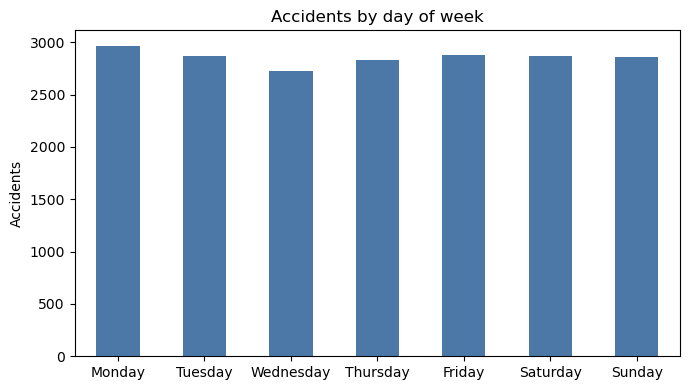

day_of_week
Monday       2966
Tuesday      2871
Wednesday    2726
Thursday     2835
Friday       2879
Saturday     2867
Sunday       2856
Name: count, dtype: int64


In [32]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = df["day_of_week"].value_counts().reindex(order)

by_day.plot(kind="bar", figsize=(7, 4), color="#4C78A8")
plt.title("Accidents by day of week")
plt.xlabel("")
plt.ylabel("Accidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print(by_day)

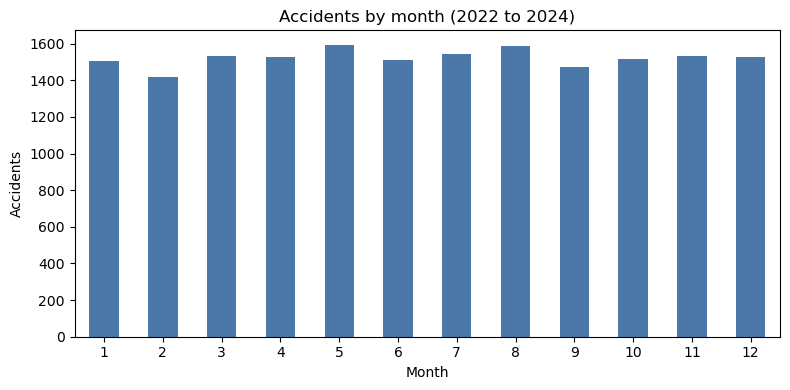

In [33]:
full_years = df[df["year"] < 2025]     # 2025 stops in April, so it would distort the months
by_month = full_years["month"].value_counts().sort_index()

by_month.plot(kind="bar", figsize=(8, 4), color="#4C78A8")
plt.title("Accidents by month (2022 to 2024)")
plt.xlabel("Month")
plt.ylabel("Accidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [34]:
from scipy.stats import chisquare

# H0: accidents are spread evenly across the categories
print("Hour    p =", round(chisquare(by_hour).pvalue, 3))
print("Weekday p =", round(chisquare(by_day).pvalue, 3))
print("Month   p =", round(chisquare(by_month).pvalue, 3))

Hour    p = 0.471
Weekday p = 0.101
Month   p = 0.162


In [35]:
city = (
    df.groupby("city")
      .agg(accidents=("accident_id", "count"),
           fatal_rate=("is_fatal", "mean"),
           avg_casualties=("casualties", "mean"),
           avg_risk=("risk_score", "mean"))
      .round(3)
)
city["fatal_rate"] = (city["fatal_rate"] * 100).round(1)

print(city.sort_values("accidents", ascending=False))

            accidents  fatal_rate  avg_casualties  avg_risk
city                                                       
Chandigarh       2577        14.7           1.698     0.442
Chennai          2575        14.4           1.774     0.438
Kolkata          2559        14.7           1.762     0.435
Pune             2517        15.8           1.756     0.436
Mumbai           2492        14.4           1.724     0.434
Bangalore        2438        15.8           1.693     0.440
Delhi            2433        15.7           1.716     0.437
Hyderabad        2409        14.0           1.685     0.439


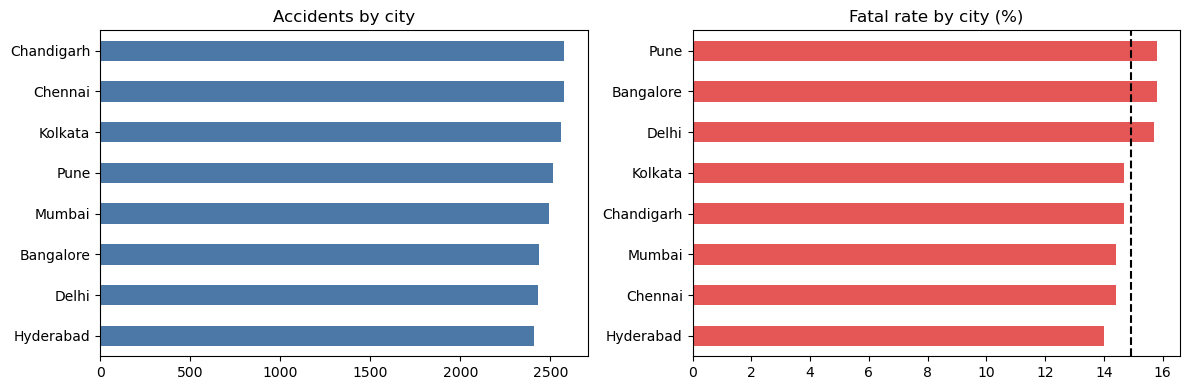

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

city["accidents"].sort_values().plot(kind="barh", ax=axes[0], color="#4C78A8")
axes[0].set_title("Accidents by city")
axes[0].set_ylabel("")

city["fatal_rate"].sort_values().plot(kind="barh", ax=axes[1], color="#E45756")
axes[1].axvline(df["is_fatal"].mean() * 100, color="black", linestyle="--")
axes[1].set_title("Fatal rate by city (%)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [37]:
from scipy.stats import chisquare, chi2_contingency, f_oneway

# Do cities have different accident counts?
print("Accident counts  p =", round(chisquare(city["accidents"]).pvalue, 3))

# Do cities have different fatal rates?
print("Fatal rate       p =", round(chi2_contingency(pd.crosstab(df["city"], df["is_fatal"]))[1], 3))

# Do cities have different average casualties? (ANOVA compares means across groups)
groups = [g["casualties"] for _, g in df.groupby("city")]
print("Casualties       p =", round(f_oneway(*groups).pvalue, 3))

Accident counts  p = 0.077
Fatal rate       p = 0.448
Casualties       p = 0.243


In [38]:
fest = (
    df.groupby("festival")
      .agg(accidents=("accident_id", "count"),
           fatal_rate=("is_fatal", "mean"),
           avg_casualties=("casualties", "mean"),
           avg_risk=("risk_score", "mean"))
      .round(3)
)
fest["fatal_rate"] = (fest["fatal_rate"] * 100).round(1)
print(fest)

             accidents  fatal_rate  avg_casualties  avg_risk
festival                                                    
Diwali              31         9.7           1.935     0.589
Eid                 34        17.6           2.088     0.603
Holi                38        34.2           2.053     0.521
New Year            12         0.0           2.083     0.521
No Festival      19885        14.9           1.725     0.437


In [39]:
from scipy.stats import ttest_ind

for flag in ["is_festival", "is_weekend", "is_peak_hour", "traffic_signal"]:
    summary = (
        df.groupby(flag)
          .agg(accidents=("accident_id", "count"),
               fatal_rate=("is_fatal", "mean"),
               avg_casualties=("casualties", "mean"),
               avg_risk=("risk_score", "mean"))
          .round(3)
    )
    print(f"--- {flag} ---")
    print(summary)

    yes, no = df[df[flag] == 1], df[df[flag] == 0]
    p_fatal = chi2_contingency(pd.crosstab(df[flag], df["is_fatal"]))[1]
    p_cas = ttest_ind(yes["casualties"], no["casualties"], equal_var=False).pvalue
    p_risk = ttest_ind(yes["risk_score"], no["risk_score"], equal_var=False).pvalue
    print(f"p-values -> fatal: {p_fatal:.3f} | casualties: {p_cas:.3f} | risk_score: {p_risk:.3f}\n")

--- is_festival ---
             accidents  fatal_rate  avg_casualties  avg_risk
is_festival                                                 
0                19885       0.149           1.725     0.437
1                  115       0.191           2.035     0.563
p-values -> fatal: 0.256 | casualties: 0.030 | risk_score: 0.000

--- is_weekend ---
            accidents  fatal_rate  avg_casualties  avg_risk
is_weekend                                                 
0               14277       0.149           1.726     0.437
1                5723       0.151           1.729     0.439
p-values -> fatal: 0.733 | casualties: 0.896 | risk_score: 0.570

--- is_peak_hour ---
              accidents  fatal_rate  avg_casualties  avg_risk
is_peak_hour                                                 
0                 15052       0.149           1.723     0.383
1                  4948       0.150           1.736     0.604
p-values -> fatal: 0.981 | casualties: 0.589 | risk_score: 0.000

--- traffi

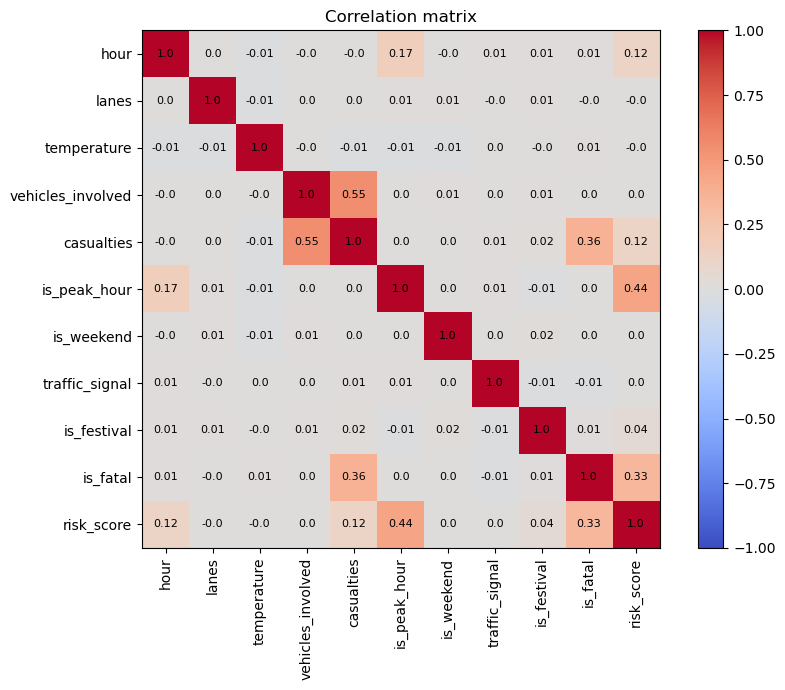

In [40]:
num_cols = ["hour", "lanes", "temperature", "vehicles_involved", "casualties",
            "is_peak_hour", "is_weekend", "traffic_signal", "is_festival",
            "is_fatal", "risk_score"]

corr = df[num_cols].corr().round(2)

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=8)
plt.colorbar(im)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

In [41]:
print(corr["risk_score"].drop("risk_score").sort_values(key=abs, ascending=False))

is_peak_hour         0.44
is_fatal             0.33
casualties           0.12
hour                 0.12
is_festival          0.04
lanes               -0.00
temperature         -0.00
vehicles_involved    0.00
traffic_signal       0.00
is_weekend           0.00
Name: risk_score, dtype: float64


In [42]:
for col in ["weather", "traffic_density", "accident_severity", "is_peak_hour"]:
    print(df.groupby(col)["risk_score"].mean().round(2), "\n")

weather
Clear    0.24
Fog      0.59
Rain     0.49
Name: risk_score, dtype: float64 

traffic_density
High      0.59
Low       0.34
Medium    0.37
Name: risk_score, dtype: float64 

accident_severity
Fatal    0.61
Major    0.41
Minor    0.41
Name: risk_score, dtype: float64 

is_peak_hour
0    0.38
1    0.60
Name: risk_score, dtype: float64 



In [43]:
import pandas as pd
import sqlite3

data = pd.read_csv("indian_roads_clean.csv", parse_dates=["date"])

# SQLite mein date text ke roop mein rehti hai, isliye YYYY-MM-DD format mein convert karo
data["date"] = data["date"].dt.strftime("%Y-%m-%d")

conn = sqlite3.connect("roads.db")                 # roads.db file ban jayegi
data.to_sql("accidents", conn, if_exists="replace", index=False)

def q(sql):
    return pd.read_sql(sql, conn)                  # query chalao, result table mein dikhao

In [45]:

import pandas as pd
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus

user = "root"
password = quote_plus("Rakesh@12345")
host = "localhost"
port = 3306
database = "roads_db"

engine = create_engine(
    f"mysql+pymysql://{user}:{password}@{host}:{port}/{database}"
)

# Connection test
with engine.connect() as conn:
    result = conn.execute(text("SELECT 1")).scalar()
    print(result)


1


In [47]:
from sqlalchemy.types import Date

data = pd.read_csv("indian_roads_clean.csv", parse_dates=["date"])

data.to_sql("accidents", engine, if_exists="replace", index=False,
            chunksize=5000, dtype={"date": Date()})

def q(sql):
    return pd.read_sql(text(sql), engine)

print("Loaded:", len(data), "rows")

Loaded: 20000 rows


In [48]:
q("SELECT COUNT(*) AS total_rows FROM accidents")

,total_rows
0,20000


In [50]:
from sqlalchemy.types import Date

data = pd.read_csv("indian_roads_clean.csv", parse_dates=["date"])
print("CSV loaded:", data.shape)

data.to_sql("accidents", engine, if_exists="replace", index=False,
            chunksize=5000, dtype={"date": Date()})
print("Table created")

def q(sql):
    return pd.read_sql(text(sql), engine)

q("SHOW TABLES")

CSV loaded: (20000, 29)
Table created


,Tables_in_roads_db
0,accidents
